# Euclid Deep Field North: Hα pilot audit
**Biswajit Jana · Day 1**

Do galaxies with stronger detected Hα emission have larger optical apertures at similar redshift and VIS brightness? This notebook reproduces the one-tile pilot’s sample audit and checks whether the available data support the study’s planned comparison. It uses real Euclid DR1-Foundation catalogue measurements. Hα flux and Kron radius are released catalogue quantities. The counts, group medians and bootstrap intervals are calculated here.

## 1. Load the analysis and small source tables
From the day directory, the notebook uses the checkout. From Colab, it downloads only the analysis files and small archived CSVs from the pinned audit revision. Change REF to audit a different revision.

In [1]:
from pathlib import Path
import sys
from urllib.request import urlopen

import pandas as pd
from IPython.display import Image, display

REF = "db395e56f4d3bce46f844b13708ba62669ee9f0e"
DAY = "euclid-dr1-foundation/2026-11-14-day01"
owner_repo = "Biswajit1999/daily-astro-notebooks"
files = (
    "analysis/scripts/audit_day01.py",
    "analysis/scripts/analyse_day01.py",
    "analysis/real_results/selected_426.csv",
    "analysis/real_results/size_matched_327.csv",
    "analysis/real_results/strict_quality_150.csv",
)
cwd = Path.cwd()
local_candidates = [cwd, cwd / DAY]
root = next((p for p in local_candidates if all((p / f).is_file() for f in files)), None)
if root is None:
    root = cwd / "euclid-day01-inputs"
    for name in files:
        request_url = f"https://raw.githubusercontent.com/{owner_repo}/{REF}/{DAY}/{name}"
        with urlopen(request_url, timeout=45) as response:
            payload = response.read()
        path = root / name
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(payload)

sys.path.insert(0, str(root / "analysis/scripts"))
import audit_day01 as analysis
print("Inputs:", root)

## 2. Reproduce the exact identifier match and imaging cuts
The cone radius is 0.15°. We preserve Euclid’s long object identifiers as strings. The matcher used tile 101834044. The imaging cut requires zero VIS and detection-quality flags, spurious probability below 0.5, and a positive finite Kron radius.

In [2]:
selected, matched, passing = analysis.validated_tables(root / "analysis/real_results")
result = analysis.audit(selected, matched, passing)
display(pd.DataFrame.from_dict(result["counts"], orient="index", columns=["Objects"]))
display(pd.Series(result["selected_by_tile"], name="Selected objects").to_frame())

,Objects
selected,426
morphology_matched,327
imaging_quality_pass,150
not_matched,99


,Selected objects
101834044,327
101834045,63
101834632,34
101834631,1
101833450,1


## 3. Compare the aperture distributions
The error bars are central 95% percentile intervals from resampling objects within each flag group. They describe within-tile median uncertainty under that resampling model. Spatial dependence and catalogue systematics are outside it.

Retained median relative to excluded: -7.5%


,n,median_px,object_bootstrap_95_px
retained,150,26.22,"[24.113489, 27.740835]"
excluded,177,28.34,"[25.648109, 30.102966]"


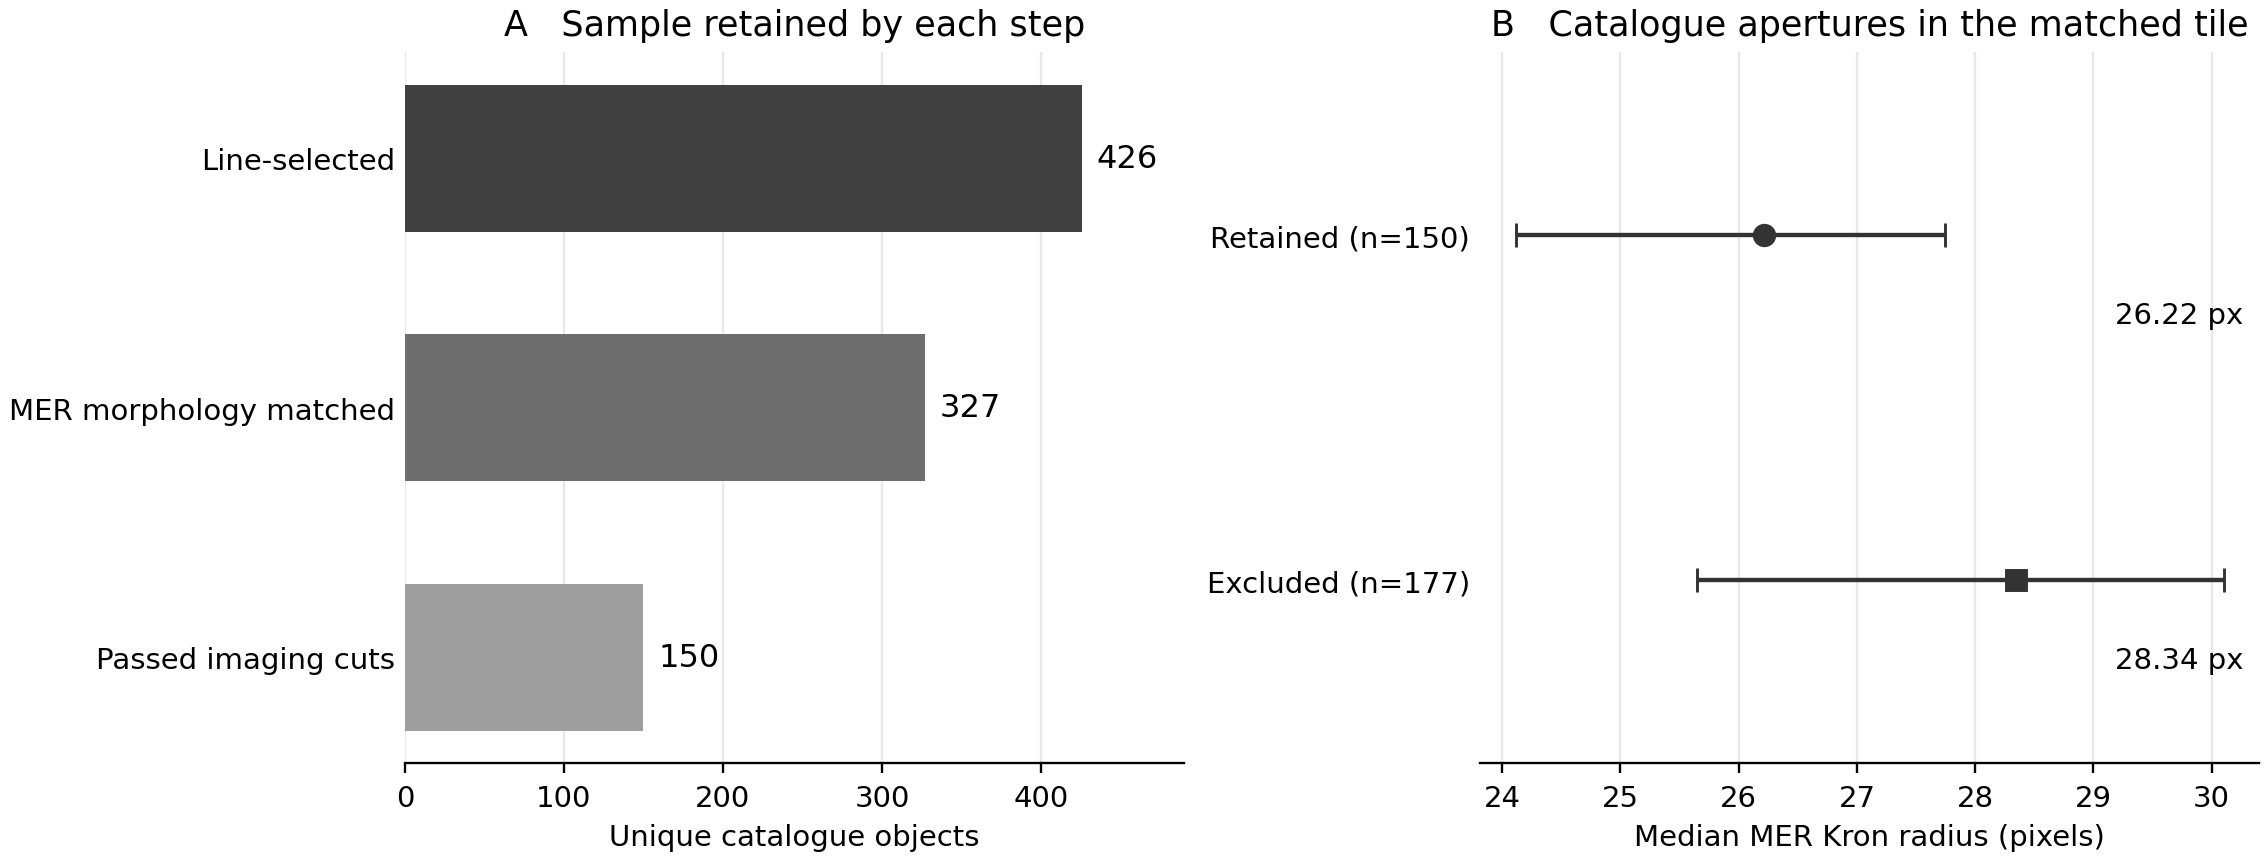

In [3]:
radius = pd.DataFrame.from_dict(result["kron_radius"], orient="index")
display(radius.round({"median_px": 2}))
print(f"Retained median relative to excluded: {result['median_pct_change_retained_vs_excluded']:.1f}%")
chart = Path("day01_sample_audit.png")
analysis.plot_audit(result, chart)
display(Image(filename=chart))

## 4. Check the study design
For each sample we construct VIS-flux tertiles inside redshift intervals. A cell needs at least 20 objects and at least 10 in each Hα half. The original comparison requires at least 200 objects that contribute to the statistic and four eligible cells.

In [4]:
check = result["comparison"]
display(pd.DataFrame.from_dict({
    "Before imaging cuts": check["before_imaging_cuts"],
    "After imaging cuts": check["after_imaging_cuts"],
}, orient="index"))
clean = check["after_imaging_cuts"]
eligible = (clean["eligible_objects"] >= check["design_minimum_objects"]
            and clean["eligible_cells"] >= check["design_minimum_cells"])
print("Meets sample-size and cell requirements:", eligible)

Meets sample-size and cell requirements: False


,eligible_cells,eligible_objects,exploratory_contrast_dex
Before imaging cuts,9,327,0.048556
After imaging cuts,3,61,NaN


## 5. Compare individual flags with the joint selection
The following counts share the same 327 matched objects. Applying a flag on its own answers how many sources it keeps, while the joint cut is the one used for the pilot. These are overlapping rules, so their rejected counts should not be added. Nearby sources can change a detection aperture. The distinct observables used by [Dunn et al.](https://arxiv.org/abs/2611.16109) and [Gabarra et al.](https://arxiv.org/abs/2611.16504) provide context for follow-up with fitted galaxy shapes and spatially resolved line maps.

In [5]:
individual = {
    "Zero VIS flag only": matched.flag_vis.eq(0),
    "Zero detection-quality flag only": matched.det_quality_flag.eq(0),
    "Spurious probability below 0.5 only": matched.spurious_prob.lt(0.5),
    "All imaging cuts": analysis.imaging_pass(matched),
}
display(pd.Series({name: int(mask.sum()) for name, mask in individual.items()},
                  name="Retained matches").to_frame())

,Retained matches
Zero VIS flag only,172
Zero detection-quality flag only,150
Spurious probability below 0.5 only,327
All imaging cuts,150


## 6. Optional check against the original archive product
To verify the archived join directly, download the [published MER final catalogue](https://nasa-irsa-euclid-dr1.s3.us-east-1.amazonaws.com/dr1/catalogs/MER_FINAL_CATALOG/101834044/EUC_MER_FINAL-CAT_TILE101834044-8358E0_20250829T054449.406866Z_00.00.fits) (about 92 MB). This optional step requires Astropy and a local FITS file. The [study README](https://github.com/Biswajit1999/daily-astro-notebooks/tree/master/euclid-dr1-foundation/2026-11-14-day01) describes the wider source reproduction.

In [6]:
MER_FITS = None  # Set to the downloaded FITS path to run this check.
if MER_FITS is not None:
    print(analysis.verify_mer(Path(MER_FITS), selected, matched))

## Interpretation
The imaging selection changes which galaxies and aperture measurements enter the comparison. The available cells fall short of the design. The one-tile pilot therefore leaves the full-field association unresolved. Try the neighbouring catalogue for tile 101834045 using the same selection rules before pooling tiles.

This work has made use of the Data Release (DR1) data from the Euclid mission of the European Space Agency (ESA). [NASA/IPAC IRSA DR1 overview](https://irsa.ipac.caltech.edu/data/Euclid/docs/overview_dr1.html) · [MER Deep](https://doi.org/10.26131/IRSA675) · [SPE galaxy candidates](https://doi.org/10.26131/IRSA696) · [SPE lines](https://doi.org/10.26131/IRSA692).